# Do More Indebted Governments Pay Higher Yields? Government Debt and 10-Year Bond Yields in 24 OECD Countries, 2000–2024

**ECON 3916 Midterm Project · Haojin Teng**


## Start here
   1. In Colab, run the cells top to bottom. Line 1 reads the two data files straight from this project’s GitHub repository (`data/`).
   2. The files in `data/` were downloaded on 2026-11-08 from FRED and the IMF; Data provenance gives the sources. Every number in the report is printed by the last code cell.

## Setup

In [28]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx
import statsmodels.formula.api as smf
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.stattools import jarque_bera
from statsmodels.stats.outliers_influence import variance_inflation_factor
from pathlib import Path

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["font.size"] = 12
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
Path("figures").mkdir(exist_ok=True)

## Data provenance

In [29]:
SOURCE_YIELDS = "FRED: OECD Main Economic Indicators, 10-year government bond yields (series IRLTLT01..M156N)"
SOURCE_WEO = "IMF World Economic Outlook, October 2026, DataMapper API (GGXWDG_NGDP, BCA_NGDPD, NGDP_RPCH, PCPIPCH)"
DOWNLOAD_DATE = "2026-11-08"   # the day the files in data/ were downloaded
REPO_RAW = "https://raw.githubusercontent.com/haojin-teng/econ3916-midterm/main/data/"

**Who collected it, for what purpose, what is missing and why?**

The OECD compiles monthly 10-year benchmark bond yields from national sources for its Main Economic Indicators (FRED republishes them), and IMF staff compile the World Economic Outlook from national statistics to monitor and forecast economies. Yields exist only where a government borrows long-term in a liquid market, so 13 OECD members lack a series from 2000; Iceland’s series is not a nominal yield, US debt for 2000 is missing, and Greece has no yield for July 2015, when its banks were closed.

## Line 1 · Where it comes from: the first read

In [30]:
# -----------------------------------------------------------
# Line 1: the first read
# -----------------------------------------------------------
# Monthly 10-year government bond yields (OECD via FRED): one row per country-month
yields = pd.read_csv(REPO_RAW + "fred_yields_monthly.csv", parse_dates=["date"])
# Debt, current account, growth, inflation (IMF WEO, Oct 2026): one row per country-year
weo = pd.read_csv(REPO_RAW + "weo_oecd.csv")

print(f"Yields shape: {yields.shape}")
print(f"WEO shape: {weo.shape}")
print(f"\nColumn types (yields):\n{yields.dtypes}")
print(f"\nColumn types (WEO):\n{weo.dtypes}")
print()
print(yields.head(3).to_string(index=False))
print(weo.head(3).to_string(index=False))

Yields shape: (16807, 3)
WEO shape: (950, 7)

Column types (yields):
date       datetime64[us]
yield10           float64
iso2                  str
dtype: object

Column types (WEO):
iso2          str
iso3          str
year        int64
debt      float64
ca        float64
growth    float64
infl      float64
dtype: object

      date  yield10 iso2
1969-07-01     5.80   AU
1969-08-01     5.79   AU
1969-09-01     5.81   AU
iso2 iso3  year  debt   ca  growth  infl
  AT  AUT  2000  66.1 -0.7     3.2   2.0
  AT  AUT  2001  67.2 -0.8     1.3   2.3
  AT  AUT  2002  67.4  2.1     1.5   1.7


## Line 2 · Its shape: what is one row?

In [31]:
# -----------------------------------------------------------
# Line 2: what is one row?
# -----------------------------------------------------------
# One row of yields is a country-month; one row of the WEO data is a country-year. Are they keys?
print("Repeated country-months in the yields:", yields.duplicated(["iso2", "date"]).sum())
print("Repeated country-years in the WEO data:", weo.duplicated(["iso2", "year"]).sum())

n_countries = yields["iso2"].nunique()
n_months = yields["date"].nunique()
print(f"\nYields: {n_countries} OECD members, {n_months} months")
print(f"Date range: {yields['date'].min().date()} to {yields['date'].max().date()}")

# When does each country's 10-year series start? (coverage)
first_month = yields.groupby("iso2")["date"].min().sort_values()
print("\nFirst month of each country's series:")
print(first_month.to_string())

Repeated country-months in the yields: 0
Repeated country-years in the WEO data: 0

Yields: 32 OECD members, 882 months
Date range: 1953-04-01 to 2026-09-01

First month of each country's series:
iso2
US   1953-04-01
BE   1955-01-01
CA   1955-01-01
CH   1955-01-01
DE   1956-05-01
NL   1959-01-01
GB   1960-01-01
FR   1960-01-01
AU   1969-07-01
NZ   1970-01-01
IE   1970-12-01
ES   1980-01-01
NO   1985-01-01
SE   1986-12-01
DK   1987-01-01
FI   1988-01-01
JP   1989-01-01
AT   1990-01-01
IT   1991-03-01
IS   1992-01-01
PT   1993-07-01
LU   1993-10-01
IL   1997-01-01
GR   1997-06-01
HU   1999-02-01
CZ   2000-04-01
SK   2000-09-01
KR   2000-10-01
PL   2001-01-01
MX   2001-07-01
SI   2002-03-01
CL   2004-07-01


## Line 3 · What is missing

In [32]:
# -----------------------------------------------------------
# Line 3: what is missing, country by country
# -----------------------------------------------------------
# OECD members with no 10-year series on FRED at all
no_series = sorted(set(weo["iso2"]) - set(yields["iso2"]))
print(f"OECD members with no series on FRED: {no_series}")

# Sample rule: the series must start by January 2000
start_by_2000 = first_month[first_month <= "2000-01-01"]
late_codes = first_month[first_month > "2000-01-01"].index.tolist()
print(f"Members whose series starts by January 2000: {len(start_by_2000)}")
print(f"Members whose series starts later: {late_codes}")

# Measurement check: does Iceland's series measure the same thing?
df_iceland = yields[yields["iso2"] == "IS"].copy()
df_iceland["year"] = df_iceland["date"].dt.year
iceland_yield = df_iceland.groupby("year")["yield10"].mean().reset_index()
iceland_infl = weo[weo["iso2"] == "IS"][["year", "infl"]]
iceland = iceland_yield.merge(iceland_infl, on="year", how="inner")
print("\nIceland: annual mean of its 10-year series vs CPI inflation (%)")
print(iceland[(iceland["year"] >= 2006) & (iceland["year"] <= 2010)].round(2).to_string(index=False))
# A nominal yield far below inflation during a crisis -> this series tracks inflation-indexed
# bonds, so it is not the same measurement as the other countries' yields. Iceland is left out.
sample_codes = sorted(set(start_by_2000.index) - {"IS"})
print(f"\nSample: {len(sample_codes)} countries -> {sample_codes}")

OECD members with no series on FRED: ['CO', 'CR', 'EE', 'LT', 'LV', 'TR']
Members whose series starts by January 2000: 25
Members whose series starts later: ['CZ', 'SK', 'KR', 'PL', 'MX', 'SI', 'CL']

Iceland: annual mean of its 10-year series vs CPI inflation (%)
 year  yield10  infl
 2006     4.38   6.7
 2007     4.96   5.1
 2008     4.30  12.7
 2009     4.30  12.0
 2010     3.49   5.4

Sample: 24 countries -> ['AT', 'AU', 'BE', 'CA', 'CH', 'DE', 'DK', 'ES', 'FI', 'FR', 'GB', 'GR', 'HU', 'IE', 'IL', 'IT', 'JP', 'LU', 'NL', 'NO', 'NZ', 'PT', 'SE', 'US']


## Line 4 · The one join

In [33]:
# -----------------------------------------------------------
# Line 4: the one join - annual yields onto the WEO country-years
# -----------------------------------------------------------
yields["year"] = yields["date"].dt.year
in_sample = yields[(yields["year"] >= 2000) & (yields["year"] <= 2024)]
in_sample = in_sample[in_sample["iso2"].isin(sample_codes)]

# Annual yield = mean of the monthly values; n_months counts how many months each mean uses
annual = in_sample.groupby(["iso2", "year"]).agg(
    yield10=("yield10", "mean"),
    n_months=("yield10", "count"),
).reset_index()

# Start from the WEO rows (every country-year) and attach the yields; one WEO row per yield row
weo_sample = weo[weo["iso2"].isin(sample_codes)]
panel = weo_sample.merge(annual, on=["iso2", "year"], how="left", indicator=True, validate="one_to_one")
print(panel["_merge"].value_counts().to_string())
panel = panel.drop(columns="_merge")
panel = panel[["iso2", "iso3", "year", "yield10", "n_months", "debt", "ca", "growth", "infl"]]

# Rule: an annual mean may miss at most one month; with fewer than 11 months it is set to missing
panel.loc[panel["n_months"] < 11, "yield10"] = np.nan

print(f"\nPanel: {panel['iso2'].nunique()} countries x {panel['year'].nunique()} years "
      f"= {panel.shape[0]} observations")

_merge
both          600
left_only       0
right_only      0

Panel: 24 countries x 25 years = 600 observations


## Line 3, second pass · What is missing after the join

In [34]:
# -----------------------------------------------------------
# Line 3, second pass: diagnose missing data in the panel
# -----------------------------------------------------------
print("Missing values per column:")
print(panel.isnull().sum())

print("\nRows with a missing variable:")
print(panel[panel["debt"].isnull() | panel["yield10"].isnull()][["iso2", "year", "yield10", "debt"]].to_string(index=False))

# Country-years whose annual yield uses fewer than 12 months
incomplete = panel[panel["n_months"] < 12]
print(f"\nCountry-years with fewer than 12 monthly yields: {len(incomplete)}")
print(incomplete[["iso2", "year", "n_months", "yield10"]].to_string(index=False))

# Which month is missing for Greece in 2015?
df_greece = in_sample[(in_sample["iso2"] == "GR") & (in_sample["year"] == 2015)]
print(f"\nGreece 2015: {len(df_greece)} of 12 months, months present: {sorted(df_greece['date'].dt.month)}")

Missing values per column:
iso2        0
iso3        0
year        0
yield10     0
n_months    0
debt        1
ca          0
growth      0
infl        0
dtype: int64

Rows with a missing variable:
iso2  year  yield10  debt
  US  2000 6.029167   NaN

Country-years with fewer than 12 monthly yields: 1
iso2  year  n_months  yield10
  GR  2015        11 9.666364

Greece 2015: 11 of 12 months, months present: [1, 2, 3, 4, 5, 6, 8, 9, 10, 11, 12]


In [35]:
# -----------------------------------------------------------
# Line 3, second pass: flag and document, then drop the MCAR row
# -----------------------------------------------------------
panel["missingness_note"] = ""
panel.loc[(panel["iso2"] == "US") & (panel["year"] == 2000), "missingness_note"] = (
    "debt missing in WEO coverage (MCAR): row dropped")
panel.loc[(panel["iso2"] == "GR") & (panel["year"] == 2015), "missingness_note"] = (
    "July missing, banks closed (MNAR): 11-month mean kept")
print(panel[panel["missingness_note"] != ""][["iso2", "year", "missingness_note"]].to_string(index=False))

df = panel.dropna(subset=["yield10", "debt", "ca", "growth", "infl"])
print(f"\nObservations with all five variables: {len(df)} of {len(panel)}")
print(f"  (Unbalanced - not every country appears in every year)")

iso2  year                                      missingness_note
  GR  2015 July missing, banks closed (MNAR): 11-month mean kept
  US  2000      debt missing in WEO coverage (MCAR): row dropped

Observations with all five variables: 599 of 600
  (Unbalanced - not every country appears in every year)


In [36]:
# -----------------------------------------------------------
# From the OECD members to the sample
# -----------------------------------------------------------
n_members = weo["iso2"].nunique()
n_with_series = yields["iso2"].nunique()
n_late = n_with_series - len(start_by_2000)
n_iceland = len(start_by_2000) - len(sample_codes)
years_label = f"{len(sample_codes)} countries x {panel['year'].nunique()} years, 2000-2024"

print(f"From {n_members} OECD members to the sample")
print(f"{'step':<50}{'countries':>11}{'country-years':>15}")
print("-" * 76)
print(f"{'OECD members':<50}{n_members:>11}")
print(f"{'No 10-year yield series on FRED':<50}{-len(no_series):>11}")
print(f"{'Series starts after January 2000':<50}{-n_late:>11}")
print(f"{'Iceland: series does not measure a nominal yield':<50}{-n_iceland:>11}")
print(f"{years_label:<50}{len(sample_codes):>11}{len(panel):>15}")
print(f"{'Debt missing (United States 2000)':<50}{'':>11}{len(df) - len(panel):>15}")
print(f"{'In the sample':<50}{len(sample_codes):>11}{len(df):>15}")

From 38 OECD members to the sample
step                                                countries  country-years
----------------------------------------------------------------------------
OECD members                                               38
No 10-year yield series on FRED                            -6
Series starts after January 2000                           -7
Iceland: series does not measure a nominal yield           -1
24 countries x 25 years, 2000-2024                         24            600
Debt missing (United States 2000)                                         -1
In the sample                                              24            599


## Section 1: The Question and the Data

**Question.** Across 24 OECD countries from 2000 to 2024, is higher government debt associated with higher 10-year government bond yields, holding inflation, the current account balance and real GDP growth constant?

**Hypothesis.** More debt raises the risk of default or of later inflation, so investors should demand a higher yield: a positive coefficient on debt.

**X.** General government gross debt, % of GDP (IMF World Economic Outlook).

**Sample rule.** OECD members whose FRED 10-year series starts by January 2000, without Iceland; years 2000–2024; drop country-years missing any of the five variables. The rule is written down before the model is run.

In [37]:
# -----------------------------------------------------------
# Section 1: Table 1 - summary statistics
# -----------------------------------------------------------
cols = ["yield10", "debt", "ca", "growth", "infl"]
table1 = df[cols].describe().T[["mean", "50%", "std", "min", "max", "count"]]
table1.columns = ["mean", "median", "std", "min", "max", "N"]
table1.index = ["10-year government bond yield (%)", "General government gross debt (% of GDP)",
                "Current account balance (% of GDP)", "Real GDP growth (%)", "CPI inflation (%)"]
print("Table 1. Summary statistics, 24 OECD countries, 2000-2024")
print(table1.round(1).to_string())

# Where the extremes are (country and year)
print()
for col in cols:
    low = df.nsmallest(1, col)[["iso2", "year", col]].values[0]
    high = df.nlargest(1, col)[["iso2", "year", col]].values[0]
    print(f"{col:<8} min {low[2]:>7.1f} ({low[0]} {low[1]})    max {high[2]:>7.1f} ({high[0]} {high[1]})")

Table 1. Summary statistics, 24 OECD countries, 2000-2024
                                          mean  median   std   min    max      N
10-year government bond yield (%)          3.2     3.2   2.3  -0.5   22.5  599.0
General government gross debt (% of GDP)  73.8    65.8  42.0   7.4  228.8  599.0
Current account balance (% of GDP)         1.2     1.2   5.5 -20.7   27.8  599.0
Real GDP growth (%)                        1.9     2.0   3.0 -10.9   24.6  599.0
CPI inflation (%)                          2.2     2.0   2.1  -1.7   17.1  599.0

yield10  min    -0.5 (CH 2020)    max    22.5 (GR 2012)
debt     min     7.4 (LU 2002)    max   228.8 (JP 2020)
ca       min   -20.7 (IE 2019)    max    27.8 (NO 2022)
growth   min   -10.9 (ES 2020)    max    24.6 (IE 2015)
infl     min    -1.7 (IE 2009)    max    17.1 (HU 2023)


In [38]:
# Section 1 self-check (from the starter)
UNIT = "country-year"
OUTCOME = "yield10"
MAIN_X = "debt"
CONTROLS = ["infl", "growth", "ca"]   # plus year dummies
print(f"Rows: {len(df):,}   One row is: {UNIT}")
print(df[[OUTCOME, MAIN_X, *CONTROLS]].isna().sum().to_string())
print(f"Skew of {OUTCOME}: {df[OUTCOME].skew():.2f}   mean {df[OUTCOME].mean():.1f}, median {df[OUTCOME].median():.1f}")

Rows: 599   One row is: country-year
yield10    0
debt       0
infl       0
growth     0
ca         0
Skew of yield10: 1.57   mean 3.2, median 3.2


## Section 2: Descriptive Evidence

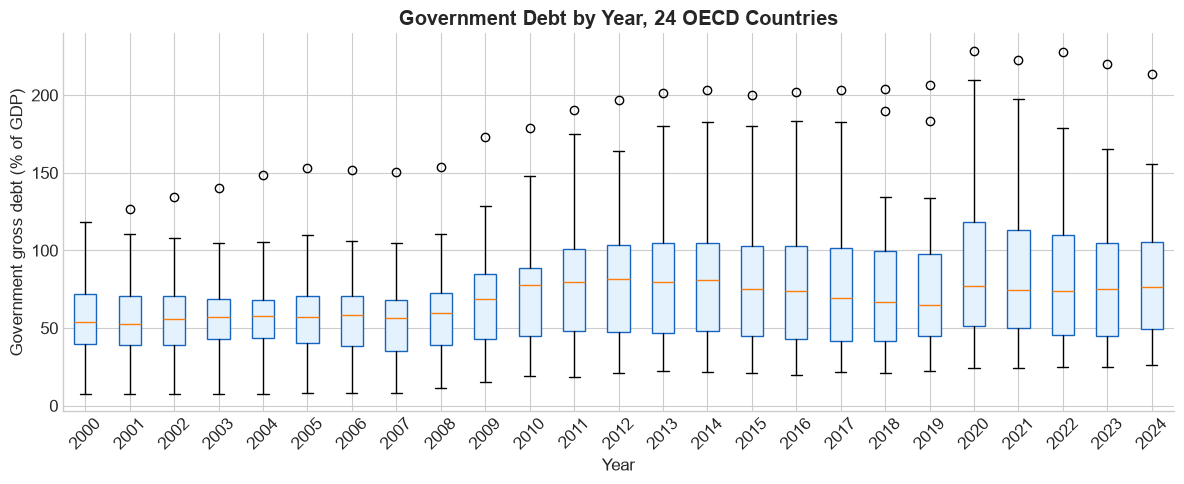

In [39]:
# -----------------------------------------------------------
# Section 2: Figure 1 - government debt by year
# -----------------------------------------------------------
years = sorted(df["year"].unique())
box_data = [df.loc[df["year"] == yr, "debt"].values for yr in years]

fig, ax = plt.subplots(figsize=(12, 5))
bp = ax.boxplot(box_data, tick_labels=[str(yr) for yr in years], patch_artist=True)
for patch in bp["boxes"]:
    patch.set_facecolor("#E3F2FD")
    patch.set_edgecolor("#1565C0")
ax.set_xlabel("Year")
ax.set_ylabel("Government gross debt (% of GDP)")
ax.set_title("Government Debt by Year, 24 OECD Countries", fontweight="bold")
ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.savefig("figures/fig1_debt_by_year.png", dpi=150, bbox_inches="tight")
plt.show()

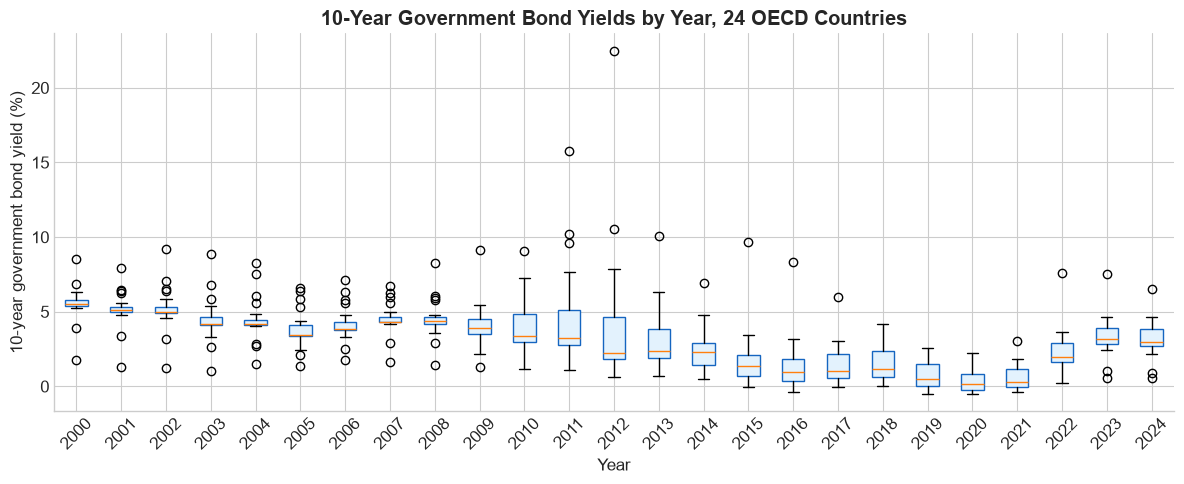

In [40]:
# -----------------------------------------------------------
# Section 2: Figure 2 - 10-year bond yields by year
# -----------------------------------------------------------
box_data = [df.loc[df["year"] == yr, "yield10"].values for yr in years]

fig, ax = plt.subplots(figsize=(12, 5))
bp = ax.boxplot(box_data, tick_labels=[str(yr) for yr in years], patch_artist=True)
for patch in bp["boxes"]:
    patch.set_facecolor("#E3F2FD")
    patch.set_edgecolor("#1565C0")
ax.set_xlabel("Year")
ax.set_ylabel("10-year government bond yield (%)")
ax.set_title("10-Year Government Bond Yields by Year, 24 OECD Countries", fontweight="bold")
ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.savefig("figures/fig2_yield_by_year.png", dpi=150, bbox_inches="tight")
plt.show()

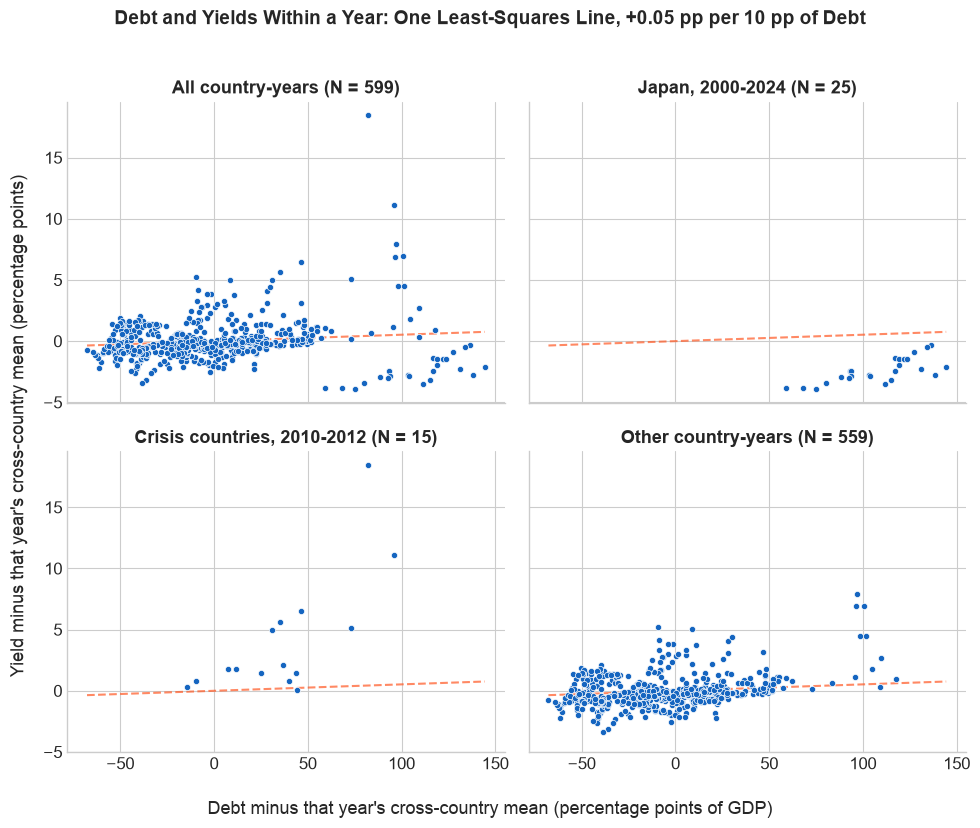

In [41]:
# -----------------------------------------------------------
# Section 2: Figure 3 - debt and yields within a year
# -----------------------------------------------------------
year_means = df.groupby("year")[["debt", "yield10"]].mean().reset_index()
year_means = year_means.rename(columns={"debt": "debt_year_mean", "yield10": "yield_year_mean"})
gaps = df.merge(year_means, on="year", how="inner")
gaps["debt_gap"] = gaps["debt"] - gaps["debt_year_mean"]
gaps["yield_gap"] = gaps["yield10"] - gaps["yield_year_mean"]

crisis_countries = ["GR", "IE", "IT", "PT", "ES"]
is_japan = gaps["iso2"] == "JP"
is_crisis = gaps["iso2"].isin(crisis_countries) & (gaps["year"] >= 2010) & (gaps["year"] <= 2012)
is_other = ~is_japan & ~is_crisis

# The shared least-squares line through all country-years, Chapter 12's closed form:
# slope = cov(x, y) / var(x), through the two means
slope = np.cov(gaps["debt_gap"], gaps["yield_gap"], ddof=1)[0, 1] / np.var(gaps["debt_gap"], ddof=1)
intercept = gaps["yield_gap"].mean() - slope * gaps["debt_gap"].mean()
x_line = np.linspace(gaps["debt_gap"].min(), gaps["debt_gap"].max(), 100)
y_line = intercept + slope * x_line

groups = [("All country-years", gaps["year"] >= 2000),
          ("Japan, 2000-2024", is_japan),
          ("Crisis countries, 2010-2012", is_crisis),
          ("Other country-years", is_other)]

fig, axes = plt.subplots(2, 2, figsize=(10, 8), sharex=True, sharey=True)
for ax, (name, mask) in zip(axes.flatten(), groups):
    subset = gaps[mask]
    ax.scatter(subset["debt_gap"], subset["yield_gap"], s=20, color="#1565C0",
               edgecolors="white", linewidth=0.5, zorder=3)
    ax.plot(x_line, y_line, color="#FF5722", linewidth=1.5, linestyle="--", alpha=0.7)
    ax.set_title(f"{name} (N = {len(subset)})", fontsize=13, fontweight="bold")

fig.supxlabel("Debt minus that year's cross-country mean (percentage points of GDP)", fontsize=13)
fig.supylabel("Yield minus that year's cross-country mean (percentage points)", fontsize=13)
fig.suptitle(f"Debt and Yields Within a Year: One Least-Squares Line, {slope * 10:+.2f} pp per 10 pp of Debt",
             fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig("figures/fig3_debt_vs_yield_within_year.png", dpi=150, bbox_inches="tight")
plt.show()

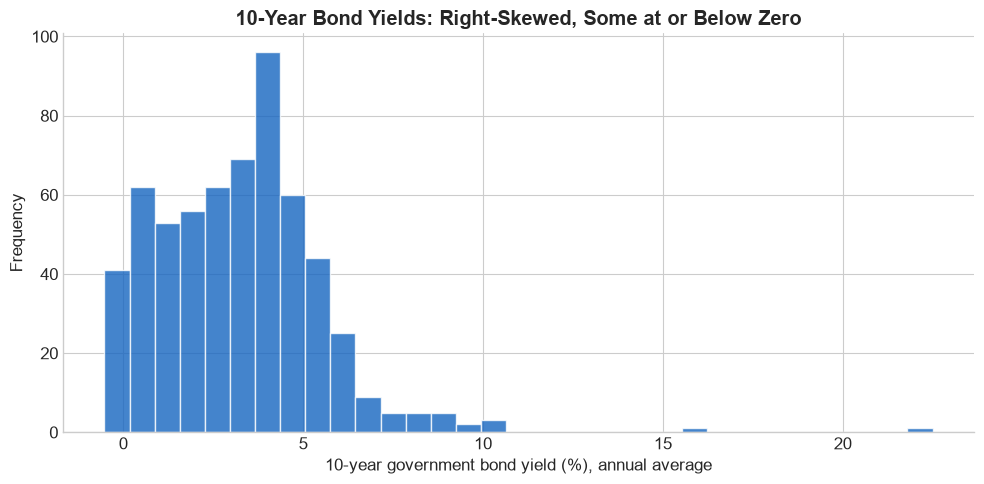

Skewness of yields: 1.57
Yields at or below 0%: 30, so a log transform is not possible


In [42]:
# -----------------------------------------------------------
# Section 2: Figure A1 - distribution of the outcome
# -----------------------------------------------------------
fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(df["yield10"], bins="fd", color="#1565C0", edgecolor="white", alpha=0.8)
ax.set_xlabel("10-year government bond yield (%), annual average")
ax.set_ylabel("Frequency")
ax.set_title("10-Year Bond Yields: Right-Skewed, Some at or Below Zero", fontweight="bold")
plt.tight_layout()
plt.savefig("figures/figA1_yield_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"Skewness of yields: {df['yield10'].skew():.2f}")
print(f"Yields at or below 0%: {(df['yield10'] <= 0).sum()}, so a log transform is not possible")

In [43]:
# -----------------------------------------------------------
# Section 2: EDA checklist - relationships and anomalies
# -----------------------------------------------------------
print("Correlation matrix:")
print(df[cols].corr().round(2))
print(f"\nDuplicate country-year pairs: {df.duplicated(subset=['iso2', 'year']).sum()}")

Correlation matrix:
         yield10  debt    ca  growth  infl
yield10     1.00 -0.06 -0.32   -0.08  0.27
debt       -0.06  1.00 -0.23   -0.21 -0.14
ca         -0.32 -0.23  1.00    0.05 -0.18
growth     -0.08 -0.21  0.05    1.00  0.15
infl        0.27 -0.14 -0.18    0.15  1.00

Duplicate country-year pairs: 0


In [44]:
# -----------------------------------------------------------
# Section 2: numbers for the captions
# -----------------------------------------------------------
median_debt = df.groupby("year")["debt"].median()
median_yield = df.groupby("year")["yield10"].median()
print("Figures 1 and 2")
for year in [2000, 2021, 2024]:
    print(f"  {year}: median debt {median_debt[year]:.0f}% of GDP, median yield {median_yield[year]:.1f}%")
print(f"  Correlation of debt and yield: all years pooled {df['debt'].corr(df['yield10']):+.2f}, "
      f"within years {gaps['debt_gap'].corr(gaps['yield_gap']):+.2f}")

print("Figure 3")
print(f"  Least-squares slope: {slope * 10:+.2f} pp of yield per 10 pp of debt")
print(f"  Japan, average gap: {gaps.loc[is_japan, 'debt_gap'].mean():+.0f} pp of debt, "
      f"{gaps.loc[is_japan, 'yield_gap'].mean():+.1f} pp of yield")
print(f"  Crisis countries 2010-2012, average gap: {gaps.loc[is_crisis, 'debt_gap'].mean():+.0f} pp of debt, "
      f"{gaps.loc[is_crisis, 'yield_gap'].mean():+.1f} pp of yield")

print("Distribution of yields")
y = df["yield10"]
print(f"  N {y.count()}, mean {y.mean():.2f}, median {y.median():.2f}, skewness {y.skew():.2f}")
print(f"  Share between 0% and 6%: {((y > 0) & (y <= 6)).mean():.1%}")
low = df[y <= 0]
high = df[y > 10]
print(f"  {len(low)} country-years at or below 0%, "
      f"{len(low[(low['year'] >= 2019) & (low['year'] <= 2021)])} of them in 2019-2021. By country:")
print(low.groupby("iso2")["year"].count().to_string())
print(f"  {len(high)} country-years above 10%:")
print(high[["iso2", "year", "yield10"]].to_string(index=False))

Figures 1 and 2
  2000: median debt 54% of GDP, median yield 5.5%
  2021: median debt 75% of GDP, median yield 0.3%
  2024: median debt 77% of GDP, median yield 3.0%
  Correlation of debt and yield: all years pooled -0.06, within years +0.13
Figure 3
  Least-squares slope: +0.05 pp of yield per 10 pp of debt
  Japan, average gap: +108 pp of debt, -2.4 pp of yield
  Crisis countries 2010-2012, average gap: +37 pp of debt, +4.2 pp of yield
Distribution of yields
  N 599, mean 3.23, median 3.21, skewness 1.57
  Share between 0% and 6%: 87.5%
  30 country-years at or below 0%, 26 of them in 2019-2021. By country:
iso2
AT    2
BE    2
CH    6
DE    3
DK    3
FI    2
FR    1
IE    1
JP    3
LU    3
NL    3
SE    1
  5 country-years above 10%:
iso2  year   yield10
  GR  2011 15.749167
  GR  2012 22.497500
  GR  2013 10.054167
  PT  2011 10.240833
  PT  2012 10.547500


## Section 3: The Model

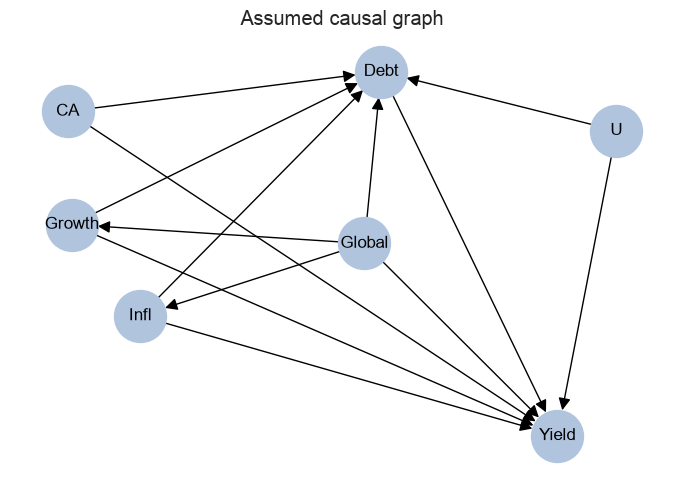

In [45]:
# -----------------------------------------------------------
# Section 3: Figure 4 - the assumed causal graph, drawn before the regressions
# -----------------------------------------------------------
# Each arrow is (from, to). Global = shocks common to every country in a year (year dummies);
# U = fixed country traits nobody measured, such as the investor base or an own currency (country dummies)
edges = [("Debt", "Yield"),
         ("Infl", "Debt"), ("Infl", "Yield"),
         ("Growth", "Debt"), ("Growth", "Yield"),
         ("Global", "Debt"), ("Global", "Yield"), ("Global", "Infl"), ("Global", "Growth"),
         ("CA", "Debt"), ("CA", "Yield"),
         ("U", "Debt"), ("U", "Yield")]
G = nx.DiGraph(edges)

fig, ax = plt.subplots(figsize=(7, 5))
pos = nx.spring_layout(G, seed=RANDOM_STATE)
nx.draw_networkx(G, pos, ax=ax, node_color="lightsteelblue", node_size=1400, arrowsize=18)
ax.set_title("Assumed causal graph")
ax.axis("off")
plt.tight_layout()
plt.savefig("figures/fig4_dag.png", dpi=150, bbox_inches="tight")
plt.show()

In [46]:
# -----------------------------------------------------------
# Section 3: fit the four OLS models
# -----------------------------------------------------------
# C(year) and C(iso2) make year and country dummies, leaving out the first of each (Chapter 13).
# Column (2) is the main specification; column (4) drops the two controls that debt may itself affect
formulas = {
    "(1)": "yield10 ~ debt + infl + growth + ca",
    "(2)": "yield10 ~ debt + infl + growth + ca + C(year)",
    "(3)": "yield10 ~ debt + infl + growth + ca + C(year) + C(iso2)",
    "(4)": "yield10 ~ debt + infl + C(year)",
}

# HC3 robust standard errors, the default Chapter 14 recommends; Section 4 shows the tests behind them
models = {}
for name, formula in formulas.items():
    models[name] = smf.ols(formula, data=df).fit(cov_type="HC3", use_t=True)
    print(f"{name}  N = {int(models[name].nobs)}, R-squared = {models[name].rsquared:.3f}:  {formula}")

(1)  N = 599, R-squared = 0.172:  yield10 ~ debt + infl + growth + ca
(2)  N = 599, R-squared = 0.563:  yield10 ~ debt + infl + growth + ca + C(year)
(3)  N = 599, R-squared = 0.808:  yield10 ~ debt + infl + growth + ca + C(year) + C(iso2)
(4)  N = 599, R-squared = 0.520:  yield10 ~ debt + infl + C(year)


In [47]:
# -----------------------------------------------------------
# Section 3: Table A1 - the regression table
# -----------------------------------------------------------
labels = {"debt": "Debt (per 10 pp of GDP)", "infl": "CPI inflation (%)",
          "growth": "Real GDP growth (%)", "ca": "Current account (% of GDP)"}
scale = {"debt": 10, "infl": 1, "growth": 1, "ca": 1}

print("Table A1. Dependent variable: 10-year government bond yield (%)")
print(f"{'':<28}{'(1)':>10}{'(2)':>10}{'(3)':>10}{'(4)':>10}")
print("-" * 68)
for var, label in labels.items():
    coef_line = f"{label:<28}"
    se_line = f"{'':<28}"
    for name, model in models.items():
        if var in model.params.index:
            se_text = f"({scale[var] * model.bse[var]:.3f})"
            coef_line += f"{scale[var] * model.params[var]:>10.3f}"
            se_line += f"{se_text:>10}"
        else:
            coef_line += f"{'':>10}"
            se_line += f"{'':>10}"
    print(coef_line)
    print(se_line)

year_line = f"{'Year dummies':<28}"
country_line = f"{'Country dummies':<28}"
n_line = f"{'Observations':<28}"
r2_line = f"{'R-squared':<28}"
for name, model in models.items():
    if "C(year)" in formulas[name]:
        year_line += f"{'Yes':>10}"
    else:
        year_line += f"{'No':>10}"
    if "C(iso2)" in formulas[name]:
        country_line += f"{'Yes':>10}"
    else:
        country_line += f"{'No':>10}"
    n_line += f"{int(model.nobs):>10}"
    r2_line += f"{model.rsquared:>10.3f}"
print("-" * 68)
print(year_line)
print(country_line)
print(n_line)
print(r2_line)
print(f"OLS on {len(df)} country-years, {df['iso2'].nunique()} OECD countries, {df['year'].min()}-{df['year'].max()}. "
      "HC3 robust standard errors in parentheses.")

Table A1. Dependent variable: 10-year government bond yield (%)
                                   (1)       (2)       (3)       (4)
--------------------------------------------------------------------
Debt (per 10 pp of GDP)         -0.067     0.023     0.278     0.079
                               (0.024)   (0.022)   (0.038)   (0.030)
CPI inflation (%)                0.242     0.305     0.052     0.425
                               (0.047)   (0.054)   (0.044)   (0.055)
Real GDP growth (%)             -0.097    -0.130    -0.229          
                               (0.050)   (0.078)   (0.080)          
Current account (% of GDP)      -0.125    -0.083     0.028          
                               (0.016)   (0.013)   (0.021)          
--------------------------------------------------------------------
Year dummies                        No       Yes       Yes       Yes
Country dummies                     No        No       Yes        No
Observations                       599 

In [48]:
# -----------------------------------------------------------
# Section 3: numbers for interpreting column (2)
# -----------------------------------------------------------
main = models["(2)"]

b = main.params["debt"]
lo, hi = main.conf_int().loc["debt"]
print(f"Debt: 10 pp of GDP more -> {10 * b:+.3f} pp of yield ({1000 * b:+.0f} basis points); "
      f"95% CI {10 * lo:+.3f} to {10 * hi:+.3f} pp; p = {main.pvalues['debt']:.3f}")
sd = df["debt"].std()
print(f"      one standard deviation of debt ({sd:.0f} pp of GDP) -> {sd * b:+.2f} pp of yield")

b = main.params["infl"]
lo, hi = main.conf_int().loc["infl"]
print(f"Inflation: 1 pp higher -> {b:+.3f} pp of yield; 95% CI {lo:+.3f} to {hi:+.3f} pp; "
      f"p = {main.pvalues['infl']:.3f}")

print("\nDebt coefficient by column (pp of yield per 10 pp of debt), HC3:")
for name, model in models.items():
    lo, hi = model.conf_int().loc["debt"]
    print(f"  {name} {10 * model.params['debt']:+.3f}  SE {10 * model.bse['debt']:.3f}  "
          f"95% CI {10 * lo:+.3f} to {10 * hi:+.3f}")

Debt: 10 pp of GDP more -> +0.023 pp of yield (+2 basis points); 95% CI -0.020 to +0.067 pp; p = 0.290
      one standard deviation of debt (42 pp of GDP) -> +0.10 pp of yield
Inflation: 1 pp higher -> +0.305 pp of yield; 95% CI +0.199 to +0.412 pp; p = 0.000

Debt coefficient by column (pp of yield per 10 pp of debt), HC3:
  (1) -0.067  SE 0.024  95% CI -0.115 to -0.019
  (2) +0.023  SE 0.022  95% CI -0.020 to +0.067
  (3) +0.278  SE 0.038  95% CI +0.203 to +0.352
  (4) +0.079  SE 0.030  95% CI +0.021 to +0.137


## Section 4: Diagnostics

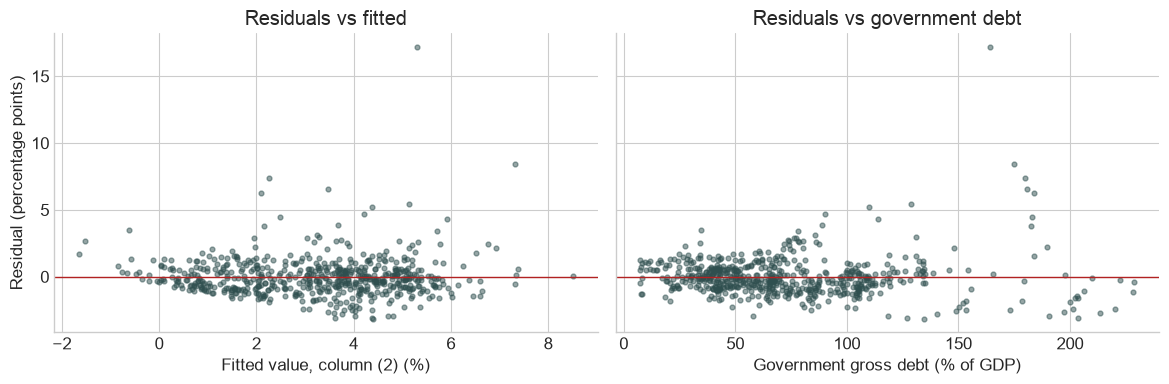

In [49]:
# -----------------------------------------------------------
# Section 4: Figure A2 - residuals against fitted values and against debt
# -----------------------------------------------------------
# The diagnostics use the classical fit of columns (2) and (3): the same coefficients, classical errors
est = df.copy()
ols = smf.ols(formulas["(2)"], data=est).fit()
ols_fe = smf.ols(formulas["(3)"], data=est).fit()
est["fitted"] = ols.fittedvalues
est["resid"] = ols.resid
est["label"] = est["iso2"] + " " + est["year"].astype(str)

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
axes[0].scatter(est["fitted"], est["resid"], s=12, alpha=0.5, color="darkslategray")
axes[0].axhline(0, color="firebrick", lw=1)
axes[0].set_xlabel("Fitted value, column (2) (%)")
axes[0].set_ylabel("Residual (percentage points)")
axes[0].set_title("Residuals vs fitted")
axes[1].scatter(est["debt"], est["resid"], s=12, alpha=0.5, color="darkslategray")
axes[1].axhline(0, color="firebrick", lw=1)
axes[1].set_xlabel("Government gross debt (% of GDP)")
axes[1].set_title("Residuals vs government debt")
plt.tight_layout()
plt.savefig("figures/figA2_residuals.png", dpi=150, bbox_inches="tight")
plt.show()

In [50]:
# -----------------------------------------------------------
# Section 4: constant variance, normality, and standard errors three ways
# -----------------------------------------------------------
is_japan = est["iso2"] == "JP"
is_crisis = est["iso2"].isin(["GR", "IE", "IT", "PT", "ES"]) & (est["year"] >= 2010) & (est["year"] <= 2012)

# Residuals by quintile (Chapter 14): a rising SD is heteroskedasticity; a pattern in the means is functional form
quintile = pd.qcut(est["fitted"], 5, labels=[1, 2, 3, 4, 5])
grouped = pd.DataFrame({"resid": est["resid"], "q": quintile}).groupby("q", observed=True)["resid"]
print("Residual SD by quintile of fitted value:")
print(grouped.std().round(2))
print("Residual mean by quintile of fitted value:")
print(grouped.mean().round(2))
debt_quintile = pd.qcut(est["debt"], 5, labels=[1, 2, 3, 4, 5])
by_debt = pd.DataFrame({"resid": est["resid"], "q": debt_quintile}).groupby("q", observed=True)["resid"]
print("Residual mean by quintile of debt:")
print(by_debt.mean().round(2))
print(f"Mean residual: Japan {est.loc[is_japan, 'resid'].mean():+.2f} pp, "
      f"crisis countries 2010-2012 {est.loc[is_crisis, 'resid'].mean():+.2f} pp")

bp = het_breuschpagan(ols.resid, ols.model.exog)
jb = jarque_bera(ols.resid)
print(f"\nBreusch-Pagan: LM = {bp[0]:.1f}, p = {bp[1]:.4f}")
print(f"Jarque-Bera:   JB = {jb[0]:.1f}, p = {jb[1]:.4f}")

# Classical, HC3, and clustered by country (each country's errors may be correlated over time)
hc3 = smf.ols(formulas["(2)"], data=est).fit(cov_type="HC3", use_t=True)
clustered = smf.ols(formulas["(2)"], data=est).fit(cov_type="cluster", cov_kwds={"groups": est["iso2"]}, use_t=True)
print("\nStandard errors three ways, column (2)")
print(f"Column (2) {'term':<8}{'coef':>9}{'classical':>11}{'HC3':>8}{'cluster':>9}{'HC3/classical':>15}{'cluster/HC3':>13}")
print("-" * 83)
for var in labels:
    k = scale[var]
    print(f"{'':<11}{var:<8}{k * ols.params[var]:>9.3f}{k * ols.bse[var]:>11.3f}{k * hc3.bse[var]:>8.3f}"
          f"{k * clustered.bse[var]:>9.3f}{hc3.bse[var] / ols.bse[var]:>15.2f}{clustered.bse[var] / hc3.bse[var]:>13.2f}")
print("(debt per 10 pp of GDP)")

clustered_fe = smf.ols(formulas["(3)"], data=est).fit(cov_type="cluster", cov_kwds={"groups": est["iso2"]}, use_t=True)
for name, fit in [("(2)", clustered), ("(3)", clustered_fe)]:
    lo, hi = fit.conf_int().loc["debt"]
    print(f"Column {name}, debt clustered by country: {10 * fit.params['debt']:+.3f}, "
          f"SE {10 * fit.bse['debt']:.3f}, 95% CI {10 * lo:+.3f} to {10 * hi:+.3f}")

Residual SD by quintile of fitted value:
q
1    0.93
2    1.46
3    1.40
4    1.33
5    2.15
Name: resid, dtype: float64
Residual mean by quintile of fitted value:
q
1    0.05
2   -0.00
3   -0.05
4   -0.22
5    0.22
Name: resid, dtype: float64
Residual mean by quintile of debt:
q
1    0.22
2   -0.10
3   -0.05
4   -0.23
5    0.15
Name: resid, dtype: float64
Mean residual: Japan -2.11 pp, crisis countries 2010-2012 +3.26 pp

Breusch-Pagan: LM = 81.3, p = 0.0000
Jarque-Bera:   JB = 25128.2, p = 0.0000

Standard errors three ways, column (2)
Column (2) term         coef  classical     HC3  cluster  HC3/classical  cluster/HC3
-----------------------------------------------------------------------------------
           debt        0.023      0.018   0.022    0.076           1.25         3.42
           infl        0.305      0.051   0.054    0.119           1.07         2.18
           growth     -0.130      0.031   0.078    0.128           2.49         1.64
           ca         -0.083    

In [51]:
# -----------------------------------------------------------
# Section 4: variance inflation factors
# -----------------------------------------------------------
# The square root of a VIF is how many times larger the standard error is than if the
# regressor were uncorrelated with the others
print("Variance inflation factors")
vifs = {}
for spec_name, fit in [("column (2)", ols), ("column (3)", ols_fe)]:
    for i, col in enumerate(fit.model.exog_names):
        if col in labels:
            vif = variance_inflation_factor(fit.model.exog, i)
            vifs[(spec_name, col)] = vif
            print(f"{spec_name}  {labels[col]:<28} VIF {vif:5.2f}   SE x{np.sqrt(vif):.2f}")

Variance inflation factors
column (2)  Debt (per 10 pp of GDP)      VIF  1.37   SE x1.17
column (2)  CPI inflation (%)            VIF  2.73   SE x1.65
column (2)  Real GDP growth (%)          VIF  2.22   SE x1.49
column (2)  Current account (% of GDP)   VIF  1.27   SE x1.13
column (3)  Debt (per 10 pp of GDP)      VIF  9.51   SE x3.08
column (3)  CPI inflation (%)            VIF  3.95   SE x1.99
column (3)  Real GDP growth (%)          VIF  2.74   SE x1.65
column (3)  Current account (% of GDP)   VIF  3.73   SE x1.93


In [52]:
# -----------------------------------------------------------
# Section 4: influence - the ten largest Cook's distances
# -----------------------------------------------------------
infl = ols.get_influence()
est["leverage"] = infl.hat_matrix_diag
est["std_resid"] = infl.resid_studentized_internal
est["cooks_d"] = infl.cooks_distance[0]
n = len(est)
p = ols.model.exog.shape[1]
print(f"Mean leverage {est['leverage'].mean():.4f} (= p/n = {p / n:.4f}); "
      f"above 3p/n: {(est['leverage'] > 3 * p / n).sum()}")
print(f"Cook's distance: largest {est['cooks_d'].max():.3f}; above 1: {(est['cooks_d'] > 1).sum()}; "
      f"above 4/n = {4 / n:.4f}: {(est['cooks_d'] > 4 / n).sum()}")

order = np.argsort(est["cooks_d"].values)[::-1][:10]       # the ten largest, largest first
print("\nThe ten largest Cook's distances, column (2)")
print(f"{'country-year':<14}{'yield':>8}{'debt':>8}{'leverage':>10}{'std resid':>11}{'Cook D':>9}")
print("-" * 60)
for i in order:
    print(f"{est['label'].iloc[i]:<14}{est['yield10'].iloc[i]:>8.2f}{est['debt'].iloc[i]:>8.1f}"
          f"{est['leverage'].iloc[i]:>10.4f}{est['std_resid'].iloc[i]:>11.3f}{est['cooks_d'].iloc[i]:>9.4f}")
share = est["cooks_d"].iloc[order].sum() / est["cooks_d"].sum()
print(f"The 10 largest hold {share:.0%} of the total Cook's distance")

# Delete the most influential rows, fit again, and compare with column (2).
# est.index[...] turns positions into row labels, and .drop() gives back a copy without those rows
for k in [1, 10]:
    trimmed = est.drop(est.index[order[:k]])
    refit = smf.ols(formulas["(2)"], data=trimmed).fit(cov_type="HC3", use_t=True)
    move = (refit.params["debt"] - hc3.params["debt"]) / hc3.bse["debt"]
    change = refit.bse["debt"] / hc3.bse["debt"] - 1
    print(f"Without the {k:>2} most influential: debt {10 * refit.params['debt']:+.3f} "
          f"(HC3 SE {10 * refit.bse['debt']:.3f}); moved {move:+.2f} of its own SE; SE changed {change:+.0%}")

Mean leverage 0.0484 (= p/n = 0.0484); above 3p/n: 2
Cook's distance: largest 0.348; above 1: 0; above 4/n = 0.0067: 24

The ten largest Cook's distances, column (2)
country-year     yield    debt  leverage  std resid   Cook D
------------------------------------------------------------
GR 2012          22.50   164.3    0.0706     11.538   0.3485
GR 2011          15.75   175.1    0.0953      5.740   0.1197
GR 2015           9.67   180.0    0.0534      4.926   0.0472
IE 2015           1.18    74.1    0.2329      1.993   0.0416
GR 2013          10.05   180.5    0.0558      4.378   0.0390
GR 2016           8.36   183.7    0.0523      4.158   0.0329
PT 2012          10.55   128.6    0.0497      3.589   0.0232
IE 2011           9.60   109.7    0.0451      3.455   0.0195
GR 2014           6.93   182.8    0.0541      2.958   0.0173
NO 2022           2.88    34.8    0.0810      2.355   0.0169
The 10 largest hold 54% of the total Cook's distance
Without the  1 most influential: debt +0.017 (HC3

In [53]:
# -----------------------------------------------------------
# Section 4: the debt coefficient without the influential groups
# -----------------------------------------------------------
est["cooks_d_fe"] = ols_fe.get_influence().cooks_distance[0]
everyone = est["year"] >= 2000
samples = [("All country-years", everyone, everyone),
           ("Without Japan", ~is_japan, ~is_japan),
           ("Without crisis countries, 2010-2012", ~is_crisis, ~is_crisis),
           ("Without Greece", est["iso2"] != "GR", est["iso2"] != "GR"),
           ("Without Cook's distance above 4/n", est["cooks_d"] <= 4 / n, est["cooks_d_fe"] <= 4 / n)]

print("Debt coefficient without the influential groups (pp of yield per 10 pp of GDP), HC3 standard errors in parentheses")
print(f"{'sample':<38}{'column (2)':>16}{'N':>6}{'column (3)':>16}{'N':>6}")
print("-" * 82)
sensitivity = {}
for label, keep2, keep3 in samples:
    m2 = smf.ols(formulas["(2)"], data=est[keep2]).fit(cov_type="HC3", use_t=True)
    m3 = smf.ols(formulas["(3)"], data=est[keep3]).fit(cov_type="HC3", use_t=True)
    sensitivity[label] = (m2, m3)
    text2 = f"{10 * m2.params['debt']:+.3f} ({10 * m2.bse['debt']:.3f})"
    text3 = f"{10 * m3.params['debt']:+.3f} ({10 * m3.bse['debt']:.3f})"
    print(f"{label:<38}{text2:>16}{int(m2.nobs):>6}{text3:>16}{int(m3.nobs):>6}")

Debt coefficient without the influential groups (pp of yield per 10 pp of GDP), HC3 standard errors in parentheses
sample                                      column (2)     N      column (3)     N
----------------------------------------------------------------------------------
All country-years                       +0.023 (0.022)   599  +0.278 (0.038)   599
Without Japan                           +0.126 (0.028)   574  +0.268 (0.044)   574
Without crisis countries, 2010-2012     +0.007 (0.020)   584  +0.245 (0.029)   584
Without Greece                          -0.020 (0.015)   574  +0.254 (0.032)   574
Without Cook's distance above 4/n       -0.009 (0.014)   575  +0.231 (0.022)   577


## Section 5: Threats and Conclusion

For the debt coefficient to be causal, nothing else that moves yields could vary with debt once the year and the controls are fixed. That fails here: Japan’s domestic investor base and central bank keep its yields low, and country dummies remove only fixed differences; central-bank bond buying lowered yields as debt rose; high yields raise interest costs and crises raise debt; and errors are correlated within countries and across euro members. Growth and the current account may also be mediators (column 4). So both estimates are **conditional associations**: column (2) compares countries in the same year, and column (3) compares years within a country. A reader can be fairly confident that the within-country association is positive, but not that debt matters across countries in the same year. With another month: allow for correlation across euro members, use start-of-year debt, and add central-bank bond holdings.

## Numbers my report quotes

In [54]:
main = models["(2)"]
low3 = min(10 * m3.params["debt"] for m2, m3 in sensitivity.values())
high3 = max(10 * m3.params["debt"] for m2, m3 in sensitivity.values())
top = est["cooks_d"].idxmax()
REPORT_NUMBERS = {
    "Line 3: OECD members": int(weo["iso2"].nunique()),
    "Line 3: no 10-year series on FRED": len(no_series),
    "Line 3: series starts after January 2000": len(late_codes),
    "Line 3: Iceland 2008, 10-year series (%)": round(iceland.loc[iceland["year"] == 2008, "yield10"].values[0], 2),
    "Line 3: Iceland 2009, 10-year series (%)": round(iceland.loc[iceland["year"] == 2009, "yield10"].values[0], 2),
    "Line 3: Iceland 2008, inflation (%)": round(iceland.loc[iceland["year"] == 2008, "infl"].values[0], 1),
    "Line 3: Iceland 2009, inflation (%)": round(iceland.loc[iceland["year"] == 2009, "infl"].values[0], 1),
    "Line 3: countries in the sample": len(sample_codes),
    "Line 4: country-years in the panel": len(panel),
    "Line 3, second pass: Greece 2015, months with a yield": len(df_greece),
    "Section 1: country-years in the sample": len(df),
    "Section 2: median debt 2000 (% of GDP)": int(round(median_debt[2000])),
    "Section 2: median debt 2024 (% of GDP)": int(round(median_debt[2024])),
    "Section 2: median yield 2000 (%)": round(median_yield[2000], 1),
    "Section 2: median yield 2021 (%)": round(median_yield[2021], 1),
    "Section 2: median yield 2024 (%)": round(median_yield[2024], 1),
    "Section 2: corr(debt, yield), all years pooled": round(df["debt"].corr(df["yield10"]), 2),
    "Section 2: corr(debt, yield), within years": round(gaps["debt_gap"].corr(gaps["yield_gap"]), 2),
    "Section 2: Figure 3 slope, pp of yield per 10 pp of debt": round(10 * slope, 2),
    "Section 2: skew of the yield": round(df["yield10"].skew(), 2),
    "Section 2: yields at or below 0%": int((df["yield10"] <= 0).sum()),
    "Section 3: debt, pp of yield per 10 pp (main)": round(10 * main.params["debt"], 3),
    "Section 3: debt, basis points per 10 pp": int(round(1000 * main.params["debt"])),
    "Section 3: debt CI low": round(10 * main.conf_int().loc["debt"][0], 3),
    "Section 3: debt CI high": round(10 * main.conf_int().loc["debt"][1], 3),
    "Section 3: debt p-value": round(main.pvalues["debt"], 3),
    "Section 3: SD of debt (pp of GDP)": int(round(df["debt"].std())),
    "Section 3: one SD of debt, pp of yield": round(df["debt"].std() * main.params["debt"], 2),
    "Section 3: inflation, pp of yield per pp": round(main.params["infl"], 3),
    "Section 3: inflation CI low": round(main.conf_int().loc["infl"][0], 3),
    "Section 3: inflation CI high": round(main.conf_int().loc["infl"][1], 3),
    "Section 3: debt, column (1)": round(10 * models["(1)"].params["debt"], 3),
    "Section 3: debt, column (3)": round(10 * models["(3)"].params["debt"], 3),
    "Section 3: debt SE, column (3)": round(10 * models["(3)"].bse["debt"], 3),
    "Section 3: debt, column (4)": round(10 * models["(4)"].params["debt"], 3),
    "Section 4: largest residual mean by fifth of fitted values": round(np.abs(grouped.mean()).max(), 2),
    "Section 4: largest residual mean by fifth of debt": round(np.abs(by_debt.mean()).max(), 2),
    "Section 4: mean residual, Japan": round(est.loc[is_japan, "resid"].mean(), 2),
    "Section 4: mean residual, crisis countries 2010-2012": round(est.loc[is_crisis, "resid"].mean(), 2),
    "Section 4: residual SD, lowest fifth of fitted values": round(grouped.std().iloc[0], 2),
    "Section 4: residual SD, highest fifth of fitted values": round(grouped.std().iloc[-1], 2),
    "Section 4: Breusch-Pagan LM": round(bp[0], 1),
    "Section 4: Breusch-Pagan p": round(bp[1], 4),
    "Section 4: debt SE clustered by country / HC3": round(clustered.bse["debt"] / hc3.bse["debt"], 1),
    "Section 4: clustered CI low, column (2)": round(10 * clustered.conf_int().loc["debt"][0], 3),
    "Section 4: clustered CI high, column (2)": round(10 * clustered.conf_int().loc["debt"][1], 3),
    "Section 4: clustered CI low, column (3)": round(10 * clustered_fe.conf_int().loc["debt"][0], 3),
    "Section 4: clustered CI high, column (3)": round(10 * clustered_fe.conf_int().loc["debt"][1], 3),
    "Section 4: largest VIF, column (2)": round(max(vifs[("column (2)", v)] for v in labels), 2),
    "Section 4: debt SE multiplier, column (2)": round(np.sqrt(vifs[("column (2)", "debt")]), 2),
    "Section 4: debt VIF, column (3)": round(vifs[("column (3)", "debt")], 2),
    "Section 4: debt SE multiplier, column (3)": round(np.sqrt(vifs[("column (3)", "debt")]), 2),
    "Section 4: Cook's distances above 1": int((est["cooks_d"] > 1).sum()),
    "Section 4: top Cook's country-year": est.loc[top, "label"],
    "Section 4: top Cook's distance": round(est.loc[top, "cooks_d"], 3),
    "Section 4: its standardised residual": round(est.loc[top, "std_resid"], 1),
    "Section 4: debt without Japan, column (2)": round(10 * sensitivity["Without Japan"][0].params["debt"], 3),
    "Section 4: debt without Greece, column (2)": round(10 * sensitivity["Without Greece"][0].params["debt"], 3),
    "Section 4: lowest debt, column (3), across samples": round(low3, 3),
    "Section 4: highest debt, column (3), across samples": round(high3, 3),
    "Section 5: debt without the crisis years, column (3)": round(10 * sensitivity["Without crisis countries, 2010-2012"][1].params["debt"], 3),
}
for name, value in REPORT_NUMBERS.items():
    print(f"{name}: {value}")

Line 3: OECD members: 38
Line 3: no 10-year series on FRED: 6
Line 3: series starts after January 2000: 7
Line 3: Iceland 2008, 10-year series (%): 4.3
Line 3: Iceland 2009, 10-year series (%): 4.3
Line 3: Iceland 2008, inflation (%): 12.7
Line 3: Iceland 2009, inflation (%): 12.0
Line 3: countries in the sample: 24
Line 4: country-years in the panel: 600
Line 3, second pass: Greece 2015, months with a yield: 11
Section 1: country-years in the sample: 599
Section 2: median debt 2000 (% of GDP): 54
Section 2: median debt 2024 (% of GDP): 77
Section 2: median yield 2000 (%): 5.5
Section 2: median yield 2021 (%): 0.3
Section 2: median yield 2024 (%): 3.0
Section 2: corr(debt, yield), all years pooled: -0.06
Section 2: corr(debt, yield), within years: 0.13
Section 2: Figure 3 slope, pp of yield per 10 pp of debt: 0.05
Section 2: skew of the yield: 1.57
Section 2: yields at or below 0%: 30
Section 3: debt, pp of yield per 10 pp (main): 0.023
Section 3: debt, basis points per 10 pp: 2
Sectio